# Results: seeds 100 to 109

## Main findings
LOW minus RANDOM at 20% removal, in percentage points, with 95% bootstrap intervals:

- clean Penguins: -0.04 [-0.39, +0.27]
- noisy Penguins: +8.51 [+7.05, +9.96]
- noisy Gaussian: +8.88 [+7.87, +9.96]

On clean data removing low-value points does not beat random removal; every interval includes zero and at 40% LOW is slightly worse (-0.59, 4 wins and 6 losses). On noisy data it clearly helps at every fraction. One exception: at 40% on noisy Penguins, seed 104 kept only 3 Chinstrap-labelled points and got Chinstrap recall 2/13.

## Method
Shapley values use full permutations: at least 2000 per run, then more until the convergence rule is met. LOW and HIGH remove the lowest or highest values; RANDOM is averaged over 30 draws. Removal fractions are 10, 20, 30 and 40%. The bootstrap resamples the ten runs (5000 draws). The intervals are descriptive, since the Penguins runs share one dataset.

The results are made by `python run_pipeline.py` and checked by `python run_checks.py`.

In [1]:
import csv, json
from pathlib import Path
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Image, display
root=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
folder=root/'results/study'
(root/'results/figures').mkdir(parents=True,exist_ok=True)
manifest=json.loads((folder/'study_manifest.json').read_text())
assert manifest['status']=='complete' and manifest['seeds']==list(range(100,110))
def read(name):
    with (folder/name).open() as f: return list(csv.DictReader(f))
summary=read('study_summary.csv'); runs=read('study_per_run.csv')
raw=read('study_removal.csv'); values=read('study_values.csv')
detection=read('study_detection_summary.csv')
assert len(summary)==12 and len(runs)==120 and len(raw)==3870 and len(values)==5600
names=['clean_penguins','noisy_penguins','noisy_gaussian']
titles=['Clean Penguins','Noisy Penguins','Noisy Gaussian']
colors={'LOW':'#1769aa','RANDOM':'#b76b00','HIGH':'#a34279'}
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
def finish(fig,name):
    fig.tight_layout();fig.savefig(root/'results/figures'/name,dpi=150,bbox_inches='tight')
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=buffer.getvalue()));plt.close(fig)
print('10 seeds; 30 valuations; 3,870 test outcomes; RANDOM averaged within each seed.')


10 seeds; 30 valuations; 3,870 test outcomes; RANDOM averaged within each seed.


## Permutations per run
Every run starts at 2000 and stops at the first check where the rule is below 0.05.

In [2]:
perms=read('study_permutations.csv')
assert len(perms)==30 and all(r['converged']=='True' for r in perms)
print(f"{'Seed':>5} "+' '.join(f'{t:>16}' for t in titles))
for seed in range(100,110):
    row={r['condition']:r for r in perms if int(r['run_seed'])==seed}
    print(f'{seed:>5} '+' '.join(f"{int(row[n]['permutations']):>16,}" for n in names))
for name,title in zip(names,titles):
    used=[int(r['permutations']) for r in perms if r['condition']==name]
    print(f'{title}: {min(used):,}–{max(used):,} permutations, {sum(u==2000 for u in used)}/10 stopped at the 2,000 minimum')

 Seed   Clean Penguins   Noisy Penguins   Noisy Gaussian
  100            3,100            2,000            2,000
  101            3,000            2,200            2,000
  102            2,800            2,000            2,000
  103            3,200            2,000            2,000
  104            3,300            2,000            2,000
  105            3,200            2,000            2,000
  106            3,300            2,000            2,000
  107            3,400            2,000            2,000
  108            3,100            2,000            2,000
  109            3,000            2,000            2,000
Clean Penguins: 2,800–3,400 permutations, 0/10 stopped at the 2,000 minimum
Noisy Penguins: 2,000–2,200 permutations, 9/10 stopped at the 2,000 minimum
Noisy Gaussian: 2,000–2,000 permutations, 10/10 stopped at the 2,000 minimum


## All removal fractions
Test accuracy in %. The difference is LOW minus RANDOM in percentage points. W/T/L counts the runs where LOW wins, ties or loses.

In [3]:
print(f"{'Condition':19} {'Remove':>7} {'LOW':>7} {'RANDOM':>7} {'HIGH':>7} {'Delta pp':>9} {'95% descriptive interval':>26} {'W/T/L':>8}")
for r in summary:
    print(f"{r['condition']:19} {float(r['fraction_requested']):7.0%} {100*float(r['low_mean']):7.2f} {100*float(r['random_mean_mean']):7.2f} {100*float(r['high_mean']):7.2f} {100*float(r['low_minus_random_mean']):+9.2f} [{100*float(r['bootstrap95_low']):+8.2f}, {100*float(r['bootstrap95_high']):+8.2f}] {r['wins']}/{r['ties']}/{r['losses']}")


Condition            Remove     LOW  RANDOM    HIGH  Delta pp   95% descriptive interval    W/T/L
clean_penguins          10%   98.84   98.81   98.26     +0.03 [   -0.30,    +0.38] 4/2/4
clean_penguins          20%   98.70   98.74   97.54     -0.04 [   -0.39,    +0.27] 6/0/4
clean_penguins          30%   98.55   98.55   97.10     +0.00 [   -0.68,    +0.63] 5/0/5
clean_penguins          40%   97.83   98.42   96.96     -0.59 [   -1.55,    +0.30] 4/0/6
noisy_penguins          10%   95.94   89.35   81.88     +6.59 [   +5.43,    +7.86] 10/0/0
noisy_penguins          20%   98.12   89.60   76.96     +8.51 [   +7.05,    +9.96] 10/0/0
noisy_penguins          30%   98.26   88.85   69.28     +9.42 [   +7.40,   +11.39] 10/0/0
noisy_penguins          40%   96.52   88.84   59.86     +7.69 [   +3.56,   +10.65] 9/0/1
noisy_gaussian          10%   78.95   73.07   65.84     +5.88 [   +5.24,    +6.57] 10/0/0
noisy_gaussian          20%   81.94   73.06   59.36     +8.88 [   +7.87,    +9.96] 10/0/0
noisy_g

## Test accuracy
Mean of ten runs with a band of one standard deviation.

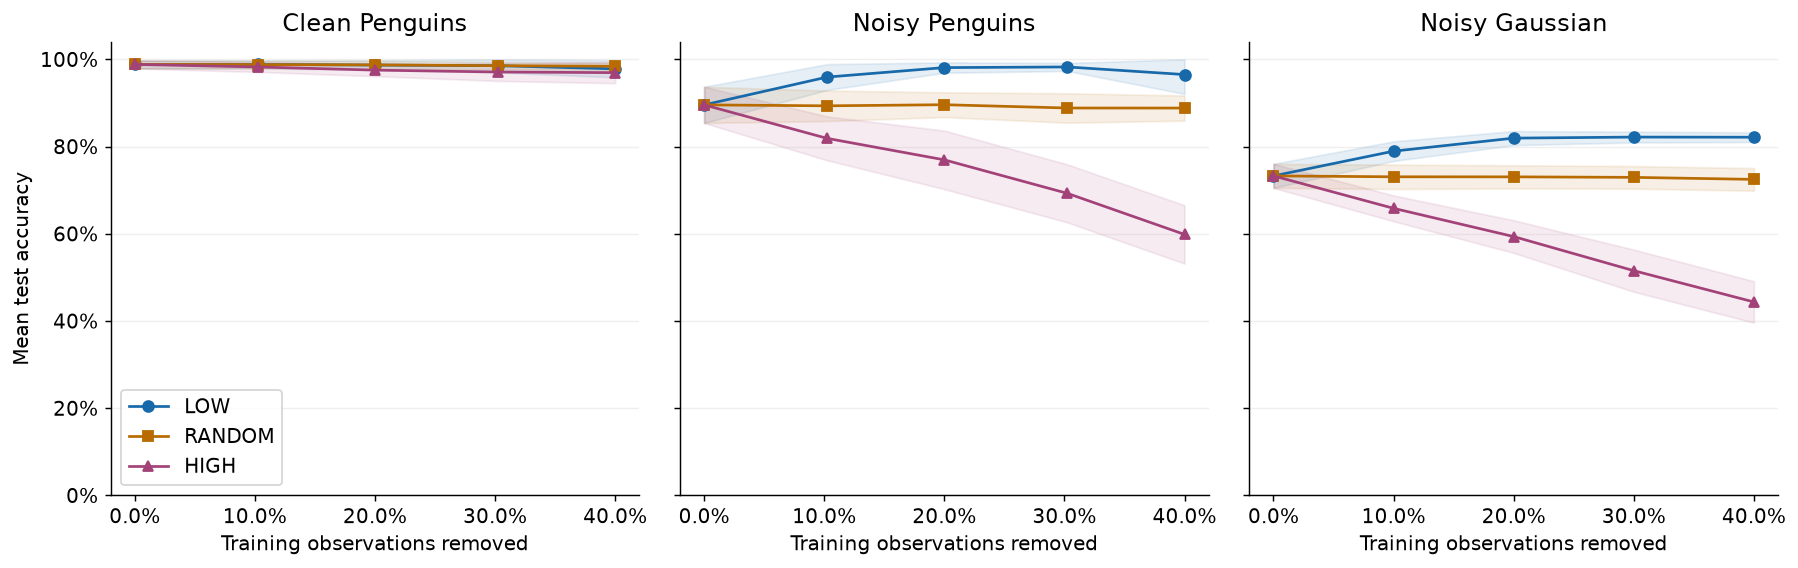

In [4]:
def accuracy_plot(relative=False):
    fig,axes=plt.subplots(1,3,figsize=(14,4.5),sharey=True)
    for name,title,ax in zip(names,titles,axes):
        rows=[r for r in summary if r['condition']==name]
        x=np.r_[0,[float(r['fraction_actual']) for r in rows]]
        baseline=1 if relative else float(rows[0]['baseline_mean'])
        base_sd=0 if relative else float(rows[0]['baseline_sd'])
        for strategy,absolute,rel,marker in [('LOW','low','low_relative','o'),('RANDOM','random_mean','random_relative','s'),('HIGH','high','high_relative','^')]:
            field=rel if relative else absolute
            y=np.r_[baseline,[float(r[field+'_mean']) for r in rows]]
            sd=np.r_[base_sd,[float(r[field+'_sd']) for r in rows]]
            ax.plot(x,y,color=colors[strategy],marker=marker,label=strategy)
            lo,hi=(y-sd,y+sd) if relative else (np.maximum(0,y-sd),np.minimum(1,y+sd))
            ax.fill_between(x,lo,hi,color=colors[strategy],alpha=.10)
        if relative: ax.axhline(1,color='#555555',ls='--',lw=1)
        else: ax.set_ylim(0,1.04);ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_title(title);ax.set_xlabel('Training observations removed')
        ax.set_xticks([0,.1,.2,.3,.4]);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.grid(axis='y',alpha=.2)
    axes[0].set_ylabel('Mean accuracy / own 0% accuracy' if relative else 'Mean test accuracy')
    axes[0].legend(loc='lower left')
    finish(fig,'study_relative_accuracy.png' if relative else 'study_accuracy.png')
accuracy_plot()


## Relative accuracy
Accuracy divided by the run's accuracy with all points kept. 1 means no change.

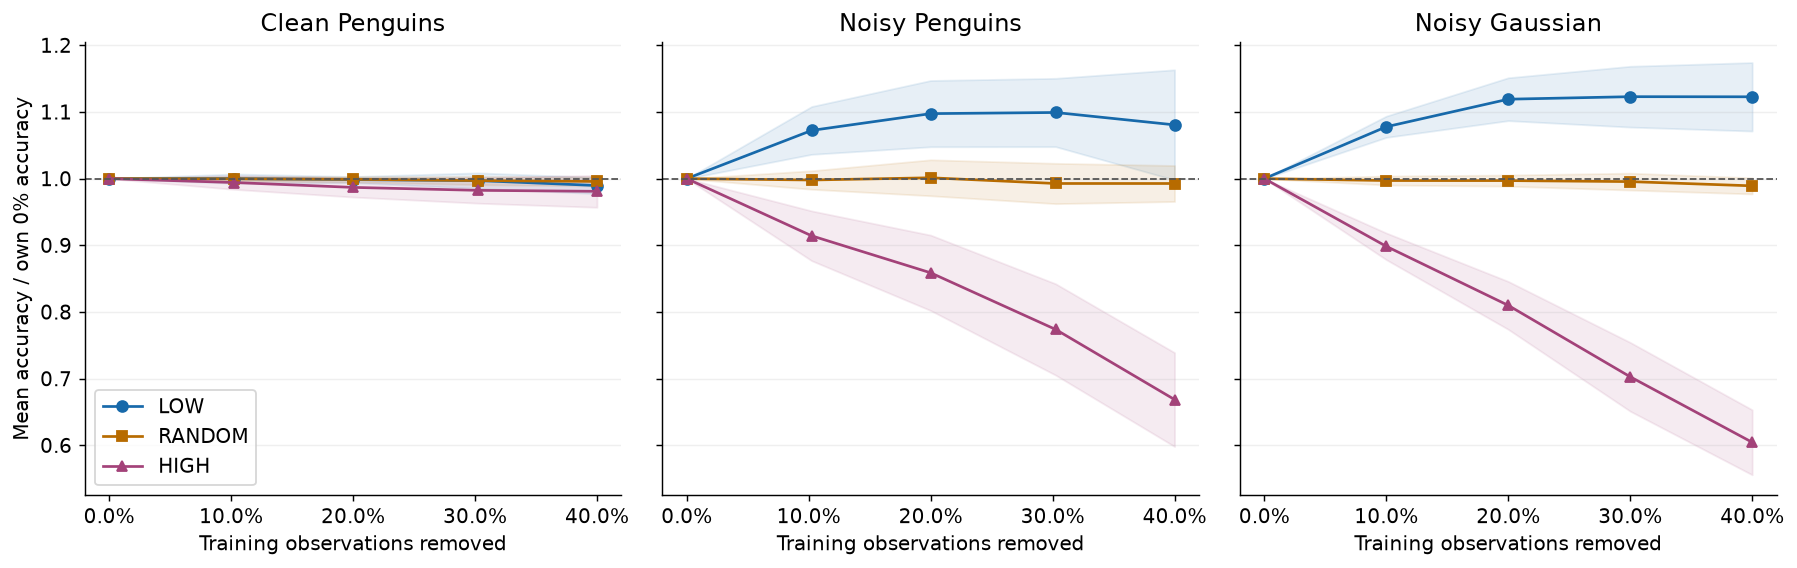

In [5]:
assert all(int(r['low_relative_defined_runs'])==10 for r in summary)
accuracy_plot(relative=True)


## LOW minus RANDOM
Mean difference with bootstrap intervals. Zero means no difference.

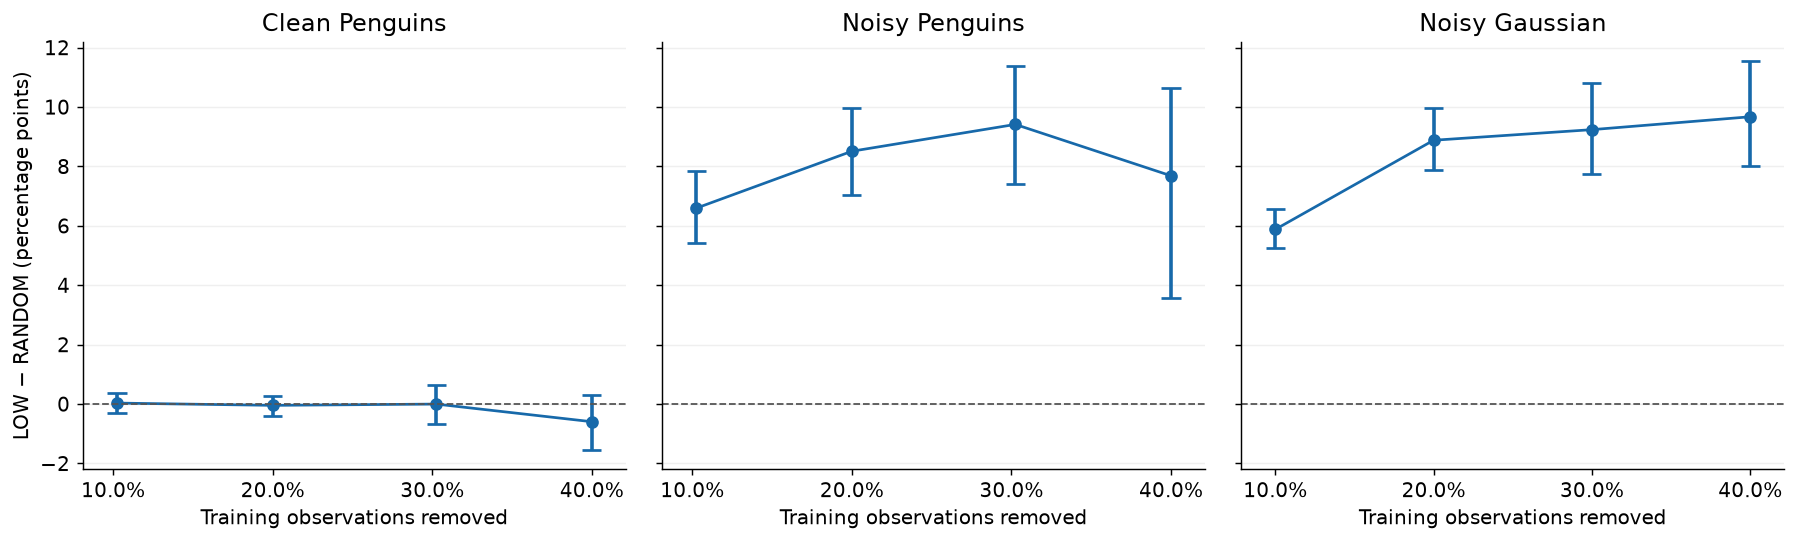

In [6]:
fig,axes=plt.subplots(1,3,figsize=(14,4.3),sharey=True)
for name,title,ax in zip(names,titles,axes):
    rows=[r for r in summary if r['condition']==name]
    x=np.array([float(r['fraction_actual']) for r in rows])
    y=np.array([float(r['low_minus_random_mean'])*100 for r in rows])
    lo=np.array([float(r['bootstrap95_low'])*100 for r in rows]);hi=np.array([float(r['bootstrap95_high'])*100 for r in rows])
    ax.plot(x,y,'o-',color='#1769aa');ax.vlines(x,lo,hi,color='#1769aa',lw=2)
    ax.hlines(lo,x-.006,x+.006,color='#1769aa');ax.hlines(hi,x-.006,x+.006,color='#1769aa')
    ax.axhline(0,color='#555555',ls='--',lw=1);ax.set_title(title);ax.grid(axis='y',alpha=.2)
    ax.set_xlabel('Training observations removed');ax.set_xticks([.1,.2,.3,.4]);ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel('LOW − RANDOM (percentage points)')
finish(fig,'study_paired_differences.png')


## Finding flipped labels
Share of flipped labels found when checking points from the lowest value up. The diagonal is random checking. Not defined for clean Penguins.

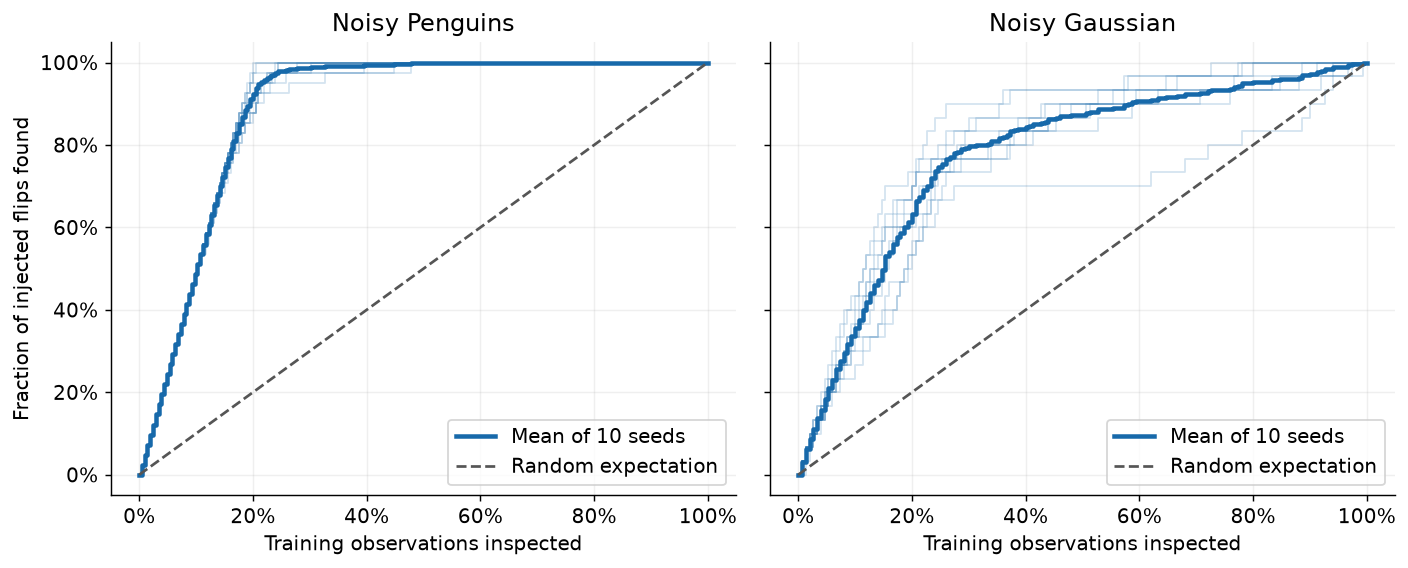

noisy_penguins: AUROC 0.993 ± 0.006; precision@10% 1.000; precision@20% 0.924
noisy_gaussian: AUROC 0.851 ± 0.058; precision@10% 0.713; precision@20% 0.633


In [7]:
records=[]
for seed in range(100,110):
    path=folder/f'seed{seed}/manifest.json'
    records.append(json.loads(path.read_text()))
fig,axes=plt.subplots(1,2,figsize=(11,4.5),sharex=True,sharey=True)
for name,title,ax in zip(names[1:],titles[1:],axes):
    curves=[]
    for record in records:
        d=record['conditions'][name]['detection'];x=np.asarray(d['fraction_inspected']);y=np.asarray(d['fraction_flips_found']);curves.append(y)
        ax.step(x,y,where='post',color='#1769aa',alpha=.18,lw=1)
    ax.step(x,np.mean(curves,axis=0),where='post',color='#1769aa',lw=2.5,label='Mean of 10 seeds')
    ax.plot([0,1],[0,1],color='#555555',ls='--',label='Random expectation')
    ax.set_title(title);ax.set_xlabel('Training observations inspected');ax.grid(alpha=.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1));ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend(loc='lower right')
axes[0].set_ylabel('Fraction of injected flips found')
finish(fig,'study_detection.png')
for r in detection:
    print(f"{r['condition']}: AUROC {float(r['auroc_mean']):.3f} ± {float(r['auroc_sd']):.3f}; precision@10% {float(r['precision10_mean']):.3f}; precision@20% {float(r['precision20_mean']):.3f}")


## Value distributions
All values from the ten runs. Outlines show the flipped points.

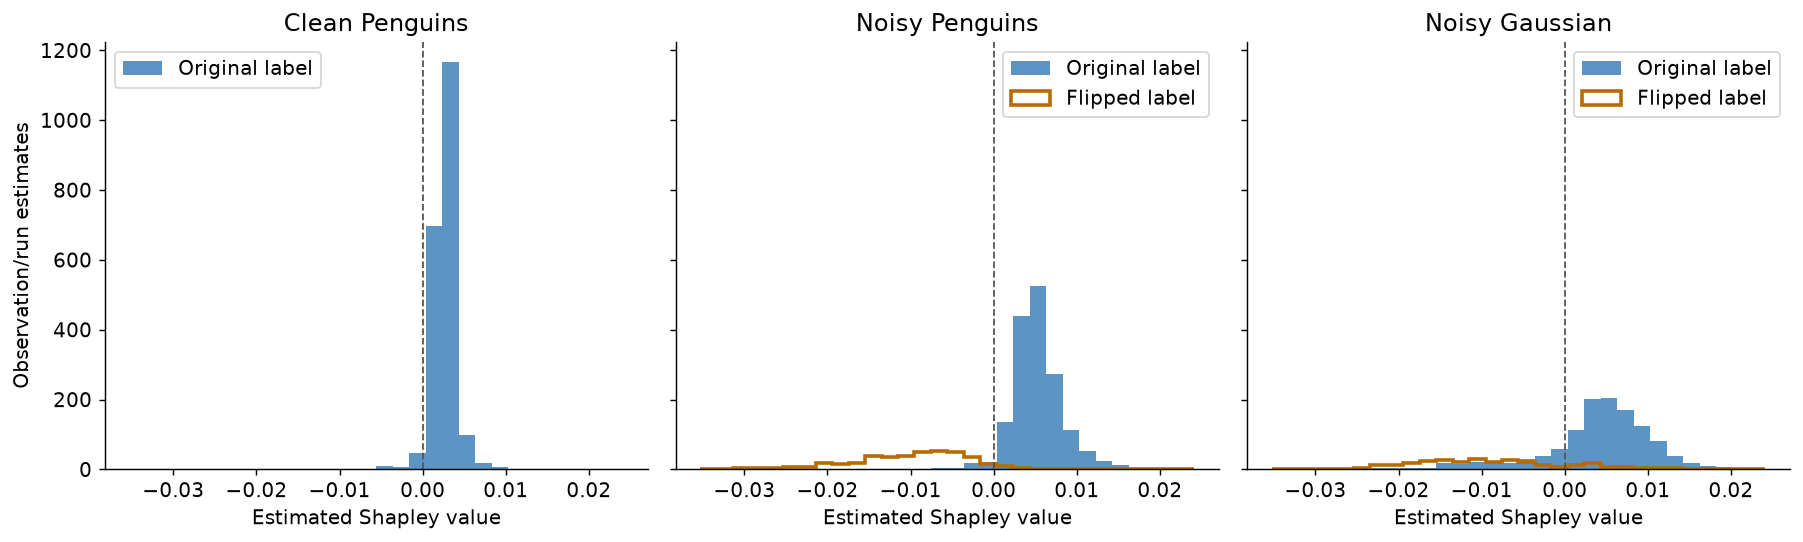

In [8]:
all_values=np.array([float(r['shapley_value']) for r in values]);bins=np.linspace(all_values.min(),all_values.max(),31)
fig,axes=plt.subplots(1,3,figsize=(14,4.3),sharex=True,sharey=True)
for name,title,ax in zip(names,titles,axes):
    group=[r for r in values if r['condition']==name]
    original=[float(r['shapley_value']) for r in group if r['corrupted_flag']=='0']
    flipped=[float(r['shapley_value']) for r in group if r['corrupted_flag']=='1']
    ax.hist(original,bins=bins,color='#1769aa',alpha=.7,label='Original label')
    if flipped: ax.hist(flipped,bins=bins,histtype='step',color='#b76b00',lw=2,label='Flipped label')
    ax.axvline(0,color='#555555',ls='--',lw=1);ax.set_title(title);ax.set_xlabel('Estimated Shapley value');ax.legend()
axes[0].set_ylabel('Observation/run estimates')
finish(fig,'study_value_distributions.png')


## Limitations
Every run meets the convergence rule, but clean-Penguins rankings are still not stable: the values are small and close, and the 68-point validation set limits how finely points can be told apart (appendix A.1). Small validation and test sets add uncertainty. The bootstrap intervals are not population guarantees.